In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import features as rf
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path

In [2]:
country_raster_1km_ = rio.open(r'../results/country-rasters/country-raster-eck4-1km.tif')
country_raster_2km_ = rio.open(r'../results/country-rasters/country-raster-eck4-2km.tif')
country_raster_5km_ = rio.open(r'../results/country-rasters/country-raster-eck4-5km.tif')
country_raster_10km_ = rio.open(r'../results/country-rasters/country-raster-eck4-10km.tif')
country_raster_50km_ = rio.open(r'../results/country-rasters/country-raster-eck4-50km.tif')

In [3]:
# TEOW = gpd.read_file(r'../data/TEOW/wwf_terr_ecos.shp')
resolve_2017 = gpd.read_file('../data/Ecoregions2017/Ecoregions2017.shp')

In [4]:
resolve_2017_eck4 = resolve_2017.to_crs('ESRI:54012')

In [4]:
resolve_2017

,OBJECTID,ECO_NAME,BIOME_NUM,BIOME_NAME,REALM,ECO_BIOME_,NNH,ECO_ID,SHAPE_LENG,SHAPE_AREA,NNH_NAME,COLOR,COLOR_BIO,COLOR_NNH,LICENSE,geometry
0,1.0,Adelie Land tundra,11.0,Tundra,Antarctica,AN11,1,117,9.749780,0.038948,Half Protected,#63CFAB,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((158.7141 -69.60657, 158.71264 ..."
1,2.0,Admiralty Islands lowland rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Australasia,AU01,2,135,4.800349,0.170599,Nature Could Reach Half Protected,#70A800,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((147.28819 -2.57589, 147.2715 -..."
2,3.0,Aegean and Western Turkey sclerophyllous and m...,12.0,"Mediterranean Forests, Woodlands & Scrub",Palearctic,PA12,4,785,162.523044,13.844952,Nature Imperiled,#FF7F7C,#FE0000,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((26.88659 35.32161, 26.88297 35..."
3,4.0,Afghan Mountains semi-desert,13.0,Deserts & Xeric Shrublands,Palearctic,PA13,4,807,15.084037,1.355536,Nature Imperiled,#FA774D,#CC6767,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((65.48655 34.71401, 65.52872 34..."
4,5.0,Ahklun and Kilbuck Upland Tundra,11.0,Tundra,Nearctic,NE11,1,404,22.590087,8.196573,Half Protected,#4C82B6,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((-160.26404 58.64097, -160.2673..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
842,848.0,Sulawesi lowland rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Australasia,AU01,2,156,150.744361,9.422097,Nature Could Reach Half Protected,#70A800,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((117.33111 -7.53306, 117.30525 ..."
843,212.0,East African montane forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,AF01,3,8,157.848926,5.010930,Nature Could Recover,#13ED00,#38A700,#F9A91B,CC-BY 4.0,"MULTIPOLYGON (((36.7375 -3.13, 36.7375 -3.1316..."
844,224.0,Eastern Arc forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,AF01,3,9,34.153333,0.890325,Nature Could Recover,#267400,#38A700,#F9A91B,CC-BY 4.0,"MULTIPOLYGON (((36.38 -8.96583, 36.38 -8.96667..."
845,79.0,Borneo montane rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Indomalayan,IN01,2,220,38.280990,9.358407,Nature Could Reach Half Protected,#23DB01,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((112.82394 -0.5066, 112.82298 -..."


In [5]:
biome_shapes_eck4 = []
for i in resolve_2017_eck4.index:
    biome_value = resolve_2017_eck4.loc[i, 'BIOME_NUM']
    a_shape = resolve_2017.loc[i, 'geometry']
    b_shape = resolve_2017_eck4.loc[i, 'geometry']
    biome_shapes_eck4.append((b_shape, biome_value))

In [7]:
biome_rst_1km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_1km_.shape, 
                             fill=0, 
                             transform=country_raster_1km_.transform,)

In [6]:
biome_rst_2km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_2km_.shape, 
                             fill=0, 
                             transform=country_raster_2km_.transform,)

In [7]:
biome_rst_5km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_5km_.shape, 
                             fill=0, 
                             transform=country_raster_5km_.transform,)

In [8]:
biome_rst_10km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_10km_.shape, 
                             fill=0, 
                             transform=country_raster_10km_.transform,)

In [9]:
biome_rst_50km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_50km_.shape, 
                             fill=0, 
                             transform=country_raster_50km_.transform,)

display results

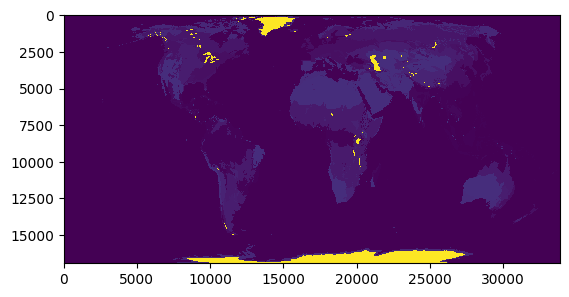

In [12]:
plt.imshow(biome_rst_1km, interpolation='nearest')
plt.show()

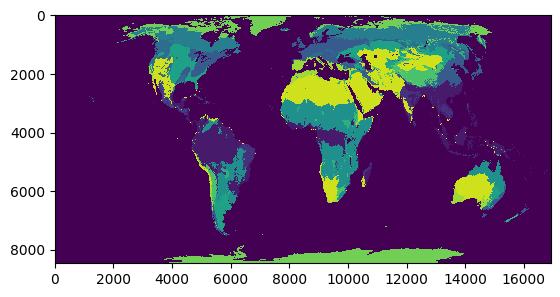

In [8]:
plt.imshow(biome_rst_2km, interpolation='nearest')
plt.show()

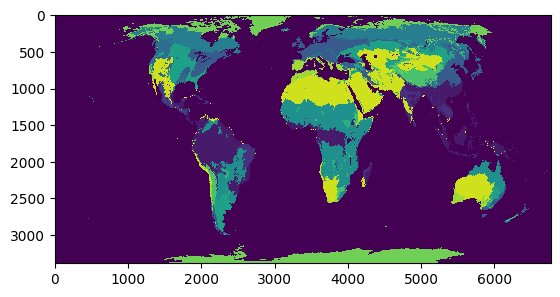

In [9]:
plt.imshow(biome_rst_5km, interpolation='nearest')
plt.show()

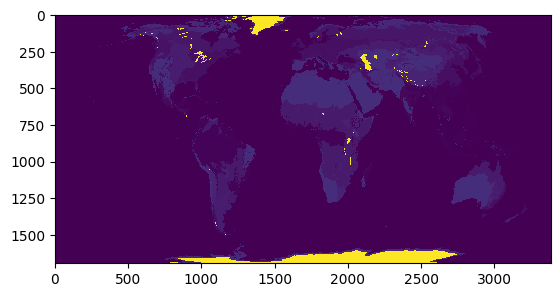

In [14]:
plt.imshow(biome_rst_10km, interpolation='nearest')
plt.show()

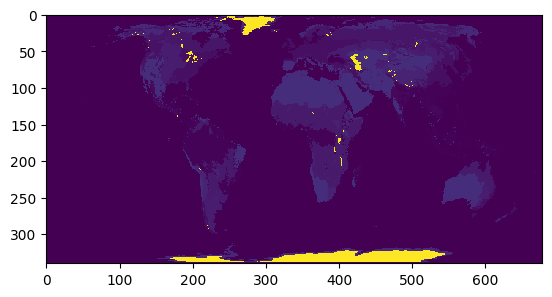

In [15]:
plt.imshow(biome_rst_50km, interpolation='nearest')
plt.show()

output results

In [13]:
Path(r'../results/biome-rasters').mkdir(parents=True, exist_ok=True)

In [10]:
with rio.open(
    r'../results/biome-rasters/resolve-biome-raster-eck4-1km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_1km.shape[0],
    width=biome_rst_1km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_1km_.crs,
    transform=country_raster_1km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_1km, 1)

In [10]:
with rio.open(
    r'../results/biome-rasters/resolve-biome-raster-eck4-2km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_2km.shape[0],
    width=biome_rst_2km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_2km_.crs,
    transform=country_raster_2km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_2km, 1)

In [11]:
with rio.open(
    r'../results/biome-rasters/resolve-biome-raster-eck4-5km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_5km.shape[0],
    width=biome_rst_5km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_5km_.crs,
    transform=country_raster_5km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_5km, 1)

In [11]:
with rio.open(
    r'../results/biome-rasters/resolve-biome-raster-eck4-10km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_10km.shape[0],
    width=biome_rst_10km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_10km_.crs,
    transform=country_raster_10km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_10km, 1)

In [12]:
with rio.open(
    r'../results/biome-rasters/resolve-biome-raster-eck4-50km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_50km.shape[0],
    width=biome_rst_50km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_50km_.crs,
    transform=country_raster_50km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_50km, 1)

In [ ]:
# 1: 'Tropical and Subtropical Moist Broadleaf Forests',
# 2: 'Tropical and Subtropical Dry Broadleaf Forests',
# 3: 'Tropical and Subtropical Coniferous Forests',
# 4: 'Temperate Broadleaf and Mixed Forests',
# 5: 'Temperate Coniferous Forests',
# 6: 'Boreal Forests/Taiga',
# 7: 'Tropical and Subtropical Grasslands, Savannas and Shrublands',
# 8: 'Temperate Grasslands, Savannas and Shrublands',
# 9: 'Flooded Grasslands and Savannas',
# 10: 'Montane Grasslands and Shrublands',
# 11: 'Tundra',
# 12: 'Mediterranean Forests, Woodlands and Scrub',
# 13: 'Deserts and Xeric Shrublands',
# 14: 'Mangroves'

In [13]:
biomes = resolve_2017.dissolve(by="BIOME_NUM", as_index=False)

In [30]:
biomes_eck4 = biomes.to_crs('ESRI:54012')

In [17]:
from cmocean import cm
colors = [cm.deep(i) for i in np.linspace(0, 1, 14)]

In [22]:
def lighten_cmap(cmap, factor=0.3):
    colors = cmap(np.linspace(0, 1, 256))
    # 提高亮度，factor 越大越接近白色
    colors[:, :3] = colors[:, :3] + (1 - colors[:, :3]) * factor
    colors = np.clip(colors, 0, 1)
    return mcolors.LinearSegmentedColormap.from_list("light_" + cmap.name, colors)

In [23]:
# 生成浅色版 colormap
light_cmap = lighten_cmap(cm.deep, factor=0.5)

In [24]:
# 取 14 个颜色
light_colors = [light_cmap(i) for i in np.linspace(0, 1, 14)]

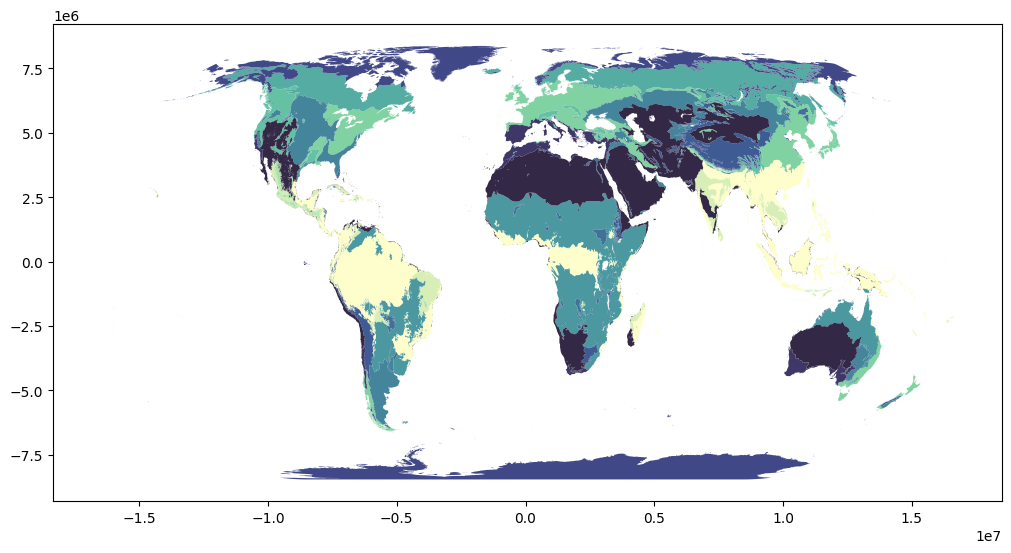

In [31]:
fig = plt.figure(figsize=(10, 8.5), constrained_layout=True)

ax1 = plt.subplot(111)
biomes_eck4.plot(color=colors, lw=0.0, alpha=1.0, ax=ax1)

plt.show()

In [32]:
biomes.to_file("../results/resolve-biomes-2017.gpkg", driver="GPKG")